<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/KL_FuseNet_Preprocessed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install --upgrade --force-reinstall sympy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 31.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 14.8 MB/s  0:00:00
  Attempting uninstall: mpmath
    Found existing installation: mpmath 1.3.0
    Uninstalling mpmath-1.3.0:
      Successfully uninstalled mpmath-1.3.0
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sympy]


In [ ]:
import sympy
import torch
import timm

print("SymPy:", sympy.__version__)
print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("CUDA available:", torch.cuda.is_available())

SymPy: 1.14.0
PyTorch: 2.14.1+cu130
timm: 1.0.31
CUDA available: True


## 1. Dataset

**What this cell does:** downloads the knee X-ray dataset and prints a few file
names to confirm the patient IDs are intact.

**What the paper did:** used 8,260 knee radiographs from 4,130 patients, taken
from a public Mendeley release organised from the Osteoarthritis Initiative
(OAI). File names follow the pattern `{patient_ID}{L|R}`, for example
`9001400L` and `9001400R` are the left and right knee of patient 9001400
(Section 2.1).

**How we applied it:** we download the Kaggle mirror of that same Mendeley
dataset, because it keeps the original file names. The printed sample proves the
patient IDs survived, which is exactly what the patient-wise split in step 5
needs.

In [ ]:
import kagglehub, os
from pathlib import Path

root = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")

names = [p.stem for p in Path(root).rglob("*") if p.suffix.lower() in [".png", ".jpg", ".jpeg"]]
print("total images:", len(names))
print("sample names:", names[:10])

Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
total images: 9786
sample names: ['9095865R', '9845238R', '9060930L', '9155763L', '9861824L', '9288025R', '9889523R', '9724907R', '9991313R', '9959748R']


## 2. Where results are saved

**What this cell does:** mounts Google Drive and creates one folder for all
outputs of this run.

**What the paper did:** not discussed; the paper does not describe its file
handling.

**How we applied it:** this is our own addition. Everything we produce (the
split table, the model weights, the checkpoints) is written to Drive, so a
dropped Colab session never costs us any work. Each experiment gets its own
folder name, so runs never overwrite each other.

In [ ]:
# --- Mount Drive and set the working directory ---
# WORK_DIR is where everything we produce is saved: tables, splits, checkpoints.

from google.colab import drive
drive.mount("/content/drive")

SEED = 42
WORK_DIR = "/content/drive/MyDrive/MUFSAL/cbam_only"
os.makedirs(WORK_DIR, exist_ok=True)
print("seed:", SEED, "| saving to:", WORK_DIR)

Mounted at /content/drive
seed: 42 | saving to: /content/drive/MyDrive/MUFSAL/cbam_only


## 3. Library install

**What this cell does:** installs `timm`.

**What the paper did:** used `timm` version 1.0.20 to load the pretrained
backbones, ConvNeXt-Base and ResNet-50 (Section 2.9).

**How we applied it:** same library. We install the current version rather than
pinning 1.0.20; the two model weights we need are published under the same names,
so the loaded weights are identical.

In [ ]:
!pip install -q timm

## 4. Imports and reproducibility

**What this cell does:** imports the libraries and fixes every random seed, so
re-running the notebook gives the same numbers.

**What the paper did:** set seed = 42 across Python, NumPy and PyTorch, and
enabled cuDNN determinism (Section 2.9).

**How we applied it:** the same four lines. We also set
`PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True` before importing torch, which
reduces GPU memory fragmentation; this is ours, not in the paper, and it does not
change any result.

In [ ]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch
import timm


# Reproducibility (paper, Section 2.9: cuDNN determinism enabled).
# SEED comes from section 2, so changing it there changes the whole run.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE, "| seed:", SEED)

Device: cuda | seed: 42


## 5. Building the image table

**What this cell does:** walks through the dataset folders and builds one table
with a row per image: its path, its KL grade, its patient ID and which knee it
is. The KL grade is taken from the name of the folder the image sits in.

**What the paper did:** worked with the 8,260 images in train + val + test, and
recovered each patient's ID by removing the trailing L/R from the file name, so
that the two knees of one patient can be kept together later (Section 2.1).

**How we applied it:** the same. We skip the `auto_test` folder, which holds a
further 1,526 images and is not part of the 8,260 the paper used. Our totals
match the paper exactly: 8,260 images, 4,130 patients, and a grade distribution
of 3253 / 1495 / 2175 / 1086 / 251, which is Table 1 of the paper. That match is
how we know we are working on the same data they were.

In [ ]:
# Build a table with one row per image.
# File names look like "9001400L" = patient 9001400, left knee.
# auto_test is skipped: the paper uses the 8260 images in train + val + test.

rows = []
for split in ["train", "val", "test"]:
    for grade in ["0", "1", "2", "3", "4"]:
        for path in Path(root).glob(f"**/{split}/{grade}/*.png"):
            rows.append({
                "path": str(path),
                "kl": int(grade),
                "orig_split": split,
                "patient_id": path.stem[:-1],      # drop the last letter (L or R)
                "side": path.stem[-1].upper(),
            })

df = pd.DataFrame(rows)

print("images:  ", len(df), "  (paper: 8260)")
print("patients:", df["patient_id"].nunique(), "  (paper: 4130)")
print("names not ending in L/R:", int((~df["side"].isin(["L", "R"])).sum()))

print("\nKL grades:")
print(df["kl"].value_counts().sort_index().to_string())

print("\nsplit sizes:")
print(df["orig_split"].value_counts().to_string())

df.head()

images:   8260   (paper: 8260)
patients: 4130   (paper: 4130)
names not ending in L/R: 0

KL grades:
kl
0    3253
1    1495
2    2175
3    1086
4     251

split sizes:
orig_split
train    5778
test     1656
val       826


,path,kl,orig_split,patient_id,side
0,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9641381,R
1,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9865771,R
2,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9133694,L
3,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9112976,L
4,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9381081,L


## 6. Patient-wise split

**What this cell does:** splits the data into training, validation and test
sets, and saves the result to `splits.csv` so every teammate uses the exact same
split.

**What the paper did:** this is the methodological core of the paper. Each
patient contributes two images (left and right knee), and those two knees look
very alike: same bone density, same machine, often the same disease stage. If one
knee lands in training and the other in testing, the model can recognise the
patient instead of the disease, and the reported score comes out too high. The
paper therefore splits by PATIENT, not by image: it labels each patient by their
highest KL grade across both knees, splits the patients 70 / 15 / 15 with
stratification and seed 42, and sends every image of a patient to the same
partition (Section 2.1).

**How we applied it:** the same four steps. `train_test_split` is called twice:
once to take 30% aside, then once to cut that 30% in half. `stratify` keeps the
grade mix roughly equal across the three parts. Our patient counts match the
paper exactly: 2,891 train, 620 validation, 619 test.

In [ ]:
from sklearn.model_selection import train_test_split

# Label each patient by their worst knee (paper: highest KL grade across both knees).
patients = df.groupby("patient_id")["kl"].max()

# Split the PATIENTS 70 / 15 / 15, keeping the grade mix equal in each part (seed 42).
train_ids, rest_ids = train_test_split(
    patients.index, test_size=0.30, stratify=patients, random_state=42)
val_ids, test_ids = train_test_split(
    rest_ids, test_size=0.50, stratify=patients[rest_ids], random_state=42)

# Both knees of a patient always land in the same split.
df["split"] = "train"
df.loc[df["patient_id"].isin(val_ids), "split"] = "val"
df.loc[df["patient_id"].isin(test_ids), "split"] = "test"

print(df.groupby("split")["patient_id"].agg(images="size", patients="nunique"))
print()
print(pd.crosstab(df["split"], df["kl"]))

df.to_csv(os.path.join(WORK_DIR, "splits.csv"), index=False)
print("\nsaved splits.csv")

       images  patients
split                  
test     1240       620
train    5782      2891
val      1238       619

kl        0     1     2    3    4
split                            
test    476   227   328  171   38
train  2293  1048  1509  756  176
val     484   220   338  159   37

saved splits.csv


mean brightness: 179.5 -> 177.8


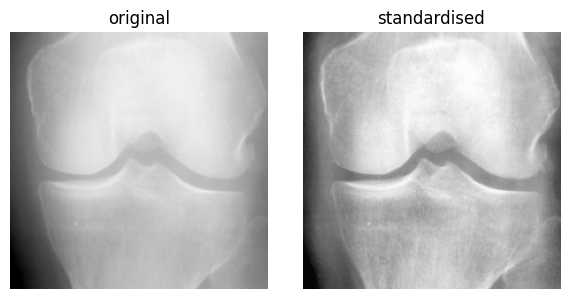

In [ ]:
import cv2
import matplotlib.pyplot as plt

# One test image to experiment on.
row = df[df["split"] == "test"].iloc[0]
original = np.array(Image.open(row["path"]).convert("L").resize((224, 224)))

# Stretch the image to a fixed range, then even out the local contrast.
lo, hi = np.percentile(original, (0.5, 99.5))
g = np.clip((original.astype(np.float32) - lo) / max(hi - lo, 1), 0, 1)
g = (5 + g * 245).astype(np.uint8)
g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)

print("mean brightness:", round(original.mean(), 1), "->", round(g.mean(), 1))

fig, (a, b) = plt.subplots(1, 2, figsize=(6, 3))
a.imshow(original, cmap="gray", vmin=0, vmax=255); a.set_title("original"); a.axis("off")
b.imshow(g, cmap="gray", vmin=0, vmax=255); b.set_title("standardised"); b.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Does brightness still differ between grades after standardising?
def standardise(path):
    g = np.array(Image.open(path).convert("L").resize((224, 224)))
    lo, hi = np.percentile(g, (0.5, 99.5))
    g = np.clip((g.astype(np.float32) - lo) / max(hi - lo, 1), 0, 1)
    g = (5 + g * 245).astype(np.uint8)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)

print("KL   before   after")
for kl in range(5):
    paths = df[(df["split"] == "train") & (df["kl"] == kl)]["path"].head(100)
    before = [np.array(Image.open(p).convert("L")).mean() for p in paths]
    after = [standardise(p).mean() for p in paths]
    print(f"{kl}   {np.mean(before):6.1f}   {np.mean(after):6.1f}")

KL   before   after
0    154.3    162.8
1    151.4    161.5
2    157.1    160.7
3    161.7    165.8
4    158.4    166.6


joint found at row: 119 out of 224


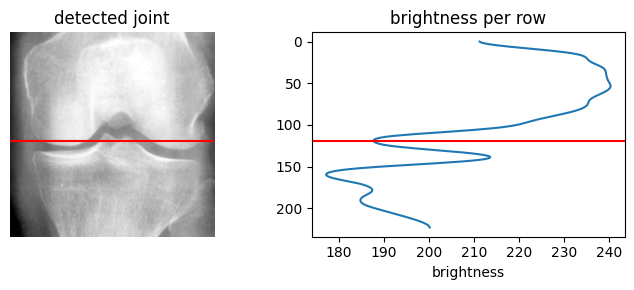

In [ ]:
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# Average the brightness of each row, using only the middle of the width.
middle = g[:, 56:168].astype(np.float32)
profile = gaussian_filter1d(np.median(middle, axis=1), sigma=4.5)

# The joint is the deepest dark valley in the band where it usually sits.
valleys, props = find_peaks(-profile[89:157], prominence=4)
joint = 124 if len(valleys) == 0 else 89 + int(valleys[np.argmax(props["prominences"])])

print("joint found at row:", joint, "out of 224")

fig, (a, b) = plt.subplots(1, 2, figsize=(7, 3))
a.imshow(g, cmap="gray"); a.axhline(joint, color="red"); a.set_title("detected joint"); a.axis("off")
b.plot(profile, range(224)); b.axhline(joint, color="red")
b.invert_yaxis(); b.set_xlabel("brightness"); b.set_title("brightness per row")
plt.tight_layout(); plt.show()

band: (104, 224) -> final: (224, 224)


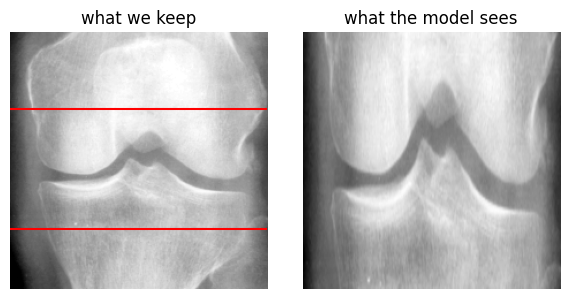

In [ ]:
# Keep 52 rows above the joint and 52 below it, then stretch back to 224.
band = g[joint - 52: joint + 52]
final = Image.fromarray(band).resize((224, 224))

print("band:", band.shape, "-> final:", final.size)

fig, (a, b) = plt.subplots(1, 2, figsize=(6, 3))
a.imshow(g, cmap="gray"); a.axhline(joint - 52, color="red"); a.axhline(joint + 52, color="red")
a.set_title("what we keep"); a.axis("off")
b.imshow(final, cmap="gray"); b.set_title("what the model sees"); b.axis("off")
plt.tight_layout(); plt.show()

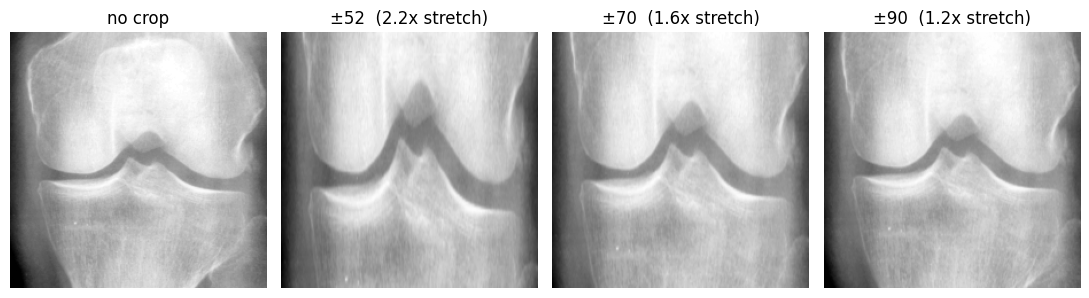

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
axes[0].imshow(g, cmap="gray"); axes[0].set_title("no crop"); axes[0].axis("off")

for ax, half in zip(axes[1:], [52, 70, 90]):
    top = max(0, joint - half)
    band = g[top: top + 2 * half]
    ax.imshow(Image.fromarray(band).resize((224, 224)), cmap="gray")
    ax.set_title(f"±{half}  ({224 / (2 * half):.1f}x stretch)")
    ax.axis("off")

plt.tight_layout(); plt.show()

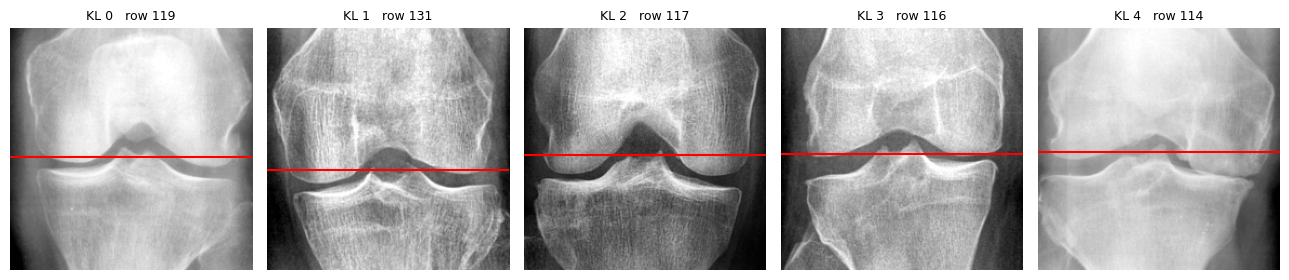

In [ ]:
# Does the detection work on every grade? KL 4 is the hard one:
# the joint space has closed, so the dark valley may not be there at all.
def find_joint(path):
    g = np.array(Image.open(path).convert("L").resize((224, 224)))
    lo, hi = np.percentile(g, (0.5, 99.5))
    g = np.clip((g.astype(np.float32) - lo) / max(hi - lo, 1), 0, 1)
    g = (5 + g * 245).astype(np.uint8)
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)

    profile = gaussian_filter1d(np.median(g[:, 56:168].astype(np.float32), axis=1), sigma=4.5)
    valleys, props = find_peaks(-profile[89:157], prominence=4)

    found = len(valleys) > 0
    row = 89 + int(valleys[np.argmax(props["prominences"])]) if found else 124
    return g, int(np.clip(row, 108, 140)), found


fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for kl, ax in zip(range(5), axes):
    path = df[(df["split"] == "test") & (df["kl"] == kl)]["path"].iloc[0]
    g, row, found = find_joint(path)
    ax.imshow(g, cmap="gray")
    ax.axhline(row, color="red" if found else "yellow")
    ax.set_title(f"KL {kl}   row {row}" + ("" if found else "   NOT FOUND"), fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Are bright pixels getting clipped at 255? That would lose bone detail.
print("KL   saturated before   after")
for kl in range(5):
    paths = df[(df["split"] == "train") & (df["kl"] == kl)]["path"].head(100)
    before, after = [], []
    for p in paths:
        raw = np.array(Image.open(p).convert("L").resize((224, 224)))
        before.append((raw >= 250).mean())
        after.append((find_joint(p)[0] >= 250).mean())
    print(f"{kl}   {100*np.mean(before):10.2f}%   {100*np.mean(after):6.2f}%")

KL   saturated before   after
0         0.07%     0.78%
1         0.23%     0.80%
2         0.11%     0.74%
3         0.55%     0.91%
4         0.49%     0.84%


In [ ]:
import cv2
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks


class JointCrop:
    """Standardise brightness, find the joint line, crop a band around it, resize to 224."""

    def __call__(self, img):
        g = np.array(img.convert("L").resize((224, 224)))

        # Give every image the same brightness and contrast, so the model cannot
        # read the grade off how bright the X-ray happens to be.
        lo, hi = np.percentile(g, (0.5, 99.5))
        g = np.clip((g.astype(np.float32) - lo) / max(hi - lo, 1), 0, 1)
        g = (5 + g * 245).astype(np.uint8)
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)

        # The joint space is the darkest horizontal line in the middle of the knee.
        profile = gaussian_filter1d(np.median(g[:, 56:168].astype(np.float32), axis=1), sigma=4.5)
        valleys, props = find_peaks(-profile[89:157], prominence=4)
        row = 89 + int(valleys[np.argmax(props["prominences"])]) if len(valleys) else 124
        row = int(np.clip(row, 108, 140))      # never trust a detection far from the usual place

        # Keep 70 rows above and below, then stretch back to the model's input size.
        band = Image.fromarray(g[row - 70: row + 70])
        return band.resize((224, 224)).convert("RGB")      # 3 channels: the rest of the pipeline needs them

## 7. Loading images and data augmentation


**Does:** turns an image into a tensor and builds the three data loaders.

**Paper (2.2):** resize to 224 x 224, normalise with ImageNet statistics, and
during training only apply four random transforms: horizontal flip p = 0.5,
rotation +-8 degrees, resized crop keeping 88-100%, brightness/contrast jitter
0.08. Validation and test get a plain resize, no randomness. The image is cut at
the midline into two halves, and the whole image and both halves pass through
the same transform stack.

**Us:** same four transforms, same parameters. The dataset returns only the FULL
image and the model cuts it in half (next cell), so both halves automatically
share the same rotation and crop. X-rays are grayscale, so we copy each one into
three channels because ImageNet normalisation expects three.

**One deviation:** the paper used batch 32; our 15 GB GPU ran out of memory, so
we use batch 16 and accumulate over two batches. Effective batch is still 32.

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

BATCH_SIZE = 16   # paper used 32; we use 16 with 2-step gradient accumulation (15 GB GPU)

# No JointCrop here: the crop experiment hurt accuracy, so this run isolates CBAM.
train_tf = T.Compose([
    T.RandomHorizontalFlip(0.5),
    T.RandomRotation(8),
    T.RandomResizedCrop(224, scale=(0.88, 1.0), ratio=(0.9, 1.1)),
    T.ColorJitter(brightness=0.08, contrast=0.08),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tf = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class KneeData(Dataset):
    def __init__(self, split, tf):
        rows = df[df["split"] == split]
        self.paths = rows["path"].tolist()
        self.labels = rows["kl"].tolist()
        self.tf = tf

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), self.labels[i]


train_loader = DataLoader(KneeData("train", train_tf), BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(KneeData("val",   eval_tf),  BATCH_SIZE, num_workers=2)
test_loader  = DataLoader(KneeData("test",  eval_tf),  BATCH_SIZE, num_workers=2)

print("images ->", len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))
x, y = next(iter(train_loader))
print("batch:", tuple(x.shape), tuple(y.shape))

images -> 5782 1238 1240
batch: (16, 3, 224, 224) (16,)


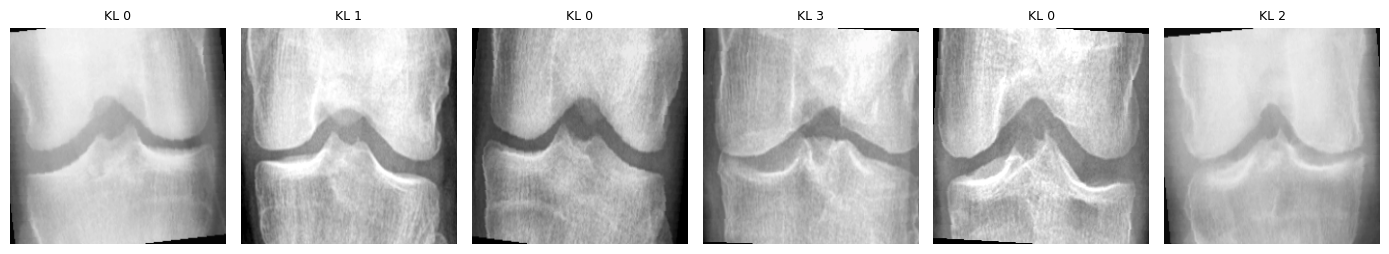

In [ ]:
# What the model actually sees: after JointCrop and the augmentation.
x, y = next(iter(train_loader))
mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std  = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
for ax, img, label in zip(axes, x, y):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(f"KL {label.item()}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Detection quality over the whole dataset, not six images.
rows_found, fallback, clipped = [], 0, 0
per_grade = {k: [0, 0] for k in range(5)}       # [total, fallback]

for path, kl in zip(df["path"], df["kl"]):
    g = np.array(Image.open(path).convert("L").resize((224, 224)))
    lo, hi = np.percentile(g, (0.5, 99.5))
    g = np.clip((g.astype(np.float32) - lo) / max(hi - lo, 1), 0, 1)
    g = (5 + g * 245).astype(np.uint8)
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)

    profile = gaussian_filter1d(np.median(g[:, 56:168].astype(np.float32), axis=1), sigma=4.5)
    valleys, props = find_peaks(-profile[89:157], prominence=4)

    per_grade[kl][0] += 1
    if len(valleys) == 0:
        fallback += 1
        per_grade[kl][1] += 1
    else:
        row = 89 + int(valleys[np.argmax(props["prominences"])])
        rows_found.append(row)
        if not (108 <= row <= 140):
            clipped += 1

print(f"images: {len(df)}")
print(f"joint found: {len(rows_found)}  |  detection failed: {fallback} ({100*fallback/len(df):.1f}%)")
print(f"found but rejected as too far: {clipped} ({100*clipped/len(df):.1f}%)")
print(f"detected row: median {np.median(rows_found):.0f}, 5th-95th {np.percentile(rows_found,5):.0f}-{np.percentile(rows_found,95):.0f}")
print("\nKL   images   failed")
for k in range(5):
    t, f = per_grade[k]
    print(f"{k}   {t:6d}   {f:5d}  ({100*f/t:.1f}%)")

images: 8260
joint found: 8213  |  detection failed: 47 (0.6%)
found but rejected as too far: 289 (3.5%)
detected row: median 120, 5th-95th 110-134

KL   images   failed
0     3253       7  (0.2%)
1     1495       1  (0.1%)
2     2175      10  (0.5%)
3     1086      16  (1.5%)
4      251      13  (5.2%)


In [ ]:
import torch.nn as nn
class CBAM(nn.Module):
    """Attention on a feature map: first WHICH channels matter, then WHERE to look."""

    def __init__(self, channels, reduction=16):
        super().__init__()
        # Channel part: squeeze each channel to one number, score it, weight it.
        self.channel = nn.Sequential(
            nn.Linear(channels, channels // reduction),
            nn.ReLU(),
            nn.Linear(channels // reduction, channels),
        )
        # Spatial part: squeeze all channels to two maps, then one weight per location.
        self.spatial = nn.Conv2d(2, 1, kernel_size=7, padding=3)

    def forward(self, x):
        b, c, _, _ = x.shape

        # --- which channels matter ---
        avg = self.channel(x.mean(dim=(2, 3)))
        mx = self.channel(x.amax(dim=(2, 3)))
        x = x * torch.sigmoid(avg + mx).view(b, c, 1, 1)

        # --- where to look ---
        maps = torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], dim=1)
        return x * torch.sigmoid(self.spatial(maps))

## 8. The KL-FuseNet model

**Does:** builds the network: three input streams, three output heads.
111.1 million parameters.

**Paper (2.3):** reading a knee X-ray needs two kinds of looking at once, the
overall joint alignment and the local detail at the joint margins. So the whole
image goes to a ConvNeXt-Base, and each half of the image goes to a ResNet-50 --
one network with shared weights, not two. The three feature vectors are pooled
with GeM (pooling whose exponent p is learned, starting at 3.0, so strong regions
count for more than plain averaging), concatenated, passed through dropout 0.1,
L2-normalised, then sent to the three heads.

**Us:** we stack both halves into one batch and run a single forward pass, then
split the result with `chunk(2)` -- this guarantees the weights really are
shared. The midline split is one line. One GeM instance serves both streams,
since its only parameter is a single number.

**`clamp` is ours, not in the paper:** GeM raises its input to the power 3, and
ConvNeXt outputs negative values, which would give NaN. We clip at a tiny
positive floor first. Worth stating in the methodology.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

USE_CBAM = True      # flip to True for the second run (crop + CBAM)


# GeM pooling (paper, Section 2.3): like average pooling, but the learnable
# exponent p lets the model emphasise the strongest regions. p starts at 3.
# clamp() is ours, not in the paper: ConvNeXt features can be negative and
# raising a negative number to a fractional power gives NaN.
class GeM(nn.Module):
    def __init__(self, p=3.0):
        super().__init__()
        self.p = nn.Parameter(torch.tensor([p]))

    def forward(self, x):
        x = x.float().clamp(min=1e-6).pow(self.p)
        return F.avg_pool2d(x, x.shape[-2:]).pow(1 / self.p).flatten(1)


class KLFuseNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Global stream: the whole image. Patch stream: shared weights, one half at a time.
        self.global_net = timm.create_model("convnext_base.fb_in22k_ft_in1k",
                                            pretrained=True, num_classes=0, global_pool="")
        self.patch_net = timm.create_model("resnet50.a1_in1k",
                                           pretrained=True, num_classes=0, global_pool="")

        # Attention on each stream, on the feature map just before pooling.
        # Identity means the model is exactly the paper's again.
        self.attn_global = CBAM(self.global_net.num_features) if USE_CBAM else nn.Identity()
        self.attn_patch = CBAM(self.patch_net.num_features) if USE_CBAM else nn.Identity()

        self.pool = GeM()
        self.dropout = nn.Dropout(0.1)

        n = self.global_net.num_features + 2 * self.patch_net.num_features   # 1024 + 2x2048
        self.head_ordinal = nn.Linear(n, 4)   # is the grade above 0, 1, 2, 3 ?
        self.head_dist = nn.Linear(n, 5)      # probability of each grade 0..4
        self.head_binary = nn.Linear(n, 1)    # KL >= 2 or not

    def forward(self, x):
        half = x.shape[-1] // 2
        left, right = x[..., :half], x[..., half:]

        f_global = self.pool(self.attn_global(self.global_net.forward_features(x)))
        f_both = self.pool(self.attn_patch(self.patch_net.forward_features(torch.cat([left, right]))))
        f_left, f_right = f_both.chunk(2)

        f = torch.cat([f_global, f_left, f_right], dim=1)
        f = F.normalize(self.dropout(f), dim=1)
        return self.head_ordinal(f), self.head_dist(f), self.head_binary(f).squeeze(1)


model = KLFuseNet().to(DEVICE)

# no_grad: this is only a shape check, so do not keep the gradient graph in memory.
with torch.no_grad():
    x, y = next(iter(val_loader))
    ordinal, dist, binary = model(x.to(DEVICE))

print("CBAM:", USE_CBAM)
print("ordinal:", tuple(ordinal.shape), "| dist:", tuple(dist.shape), "| binary:", tuple(binary.shape))
print("parameters:", round(sum(p.numel() for p in model.parameters()) / 1e6, 1), "M")

model.safetensors: reconstructing file:   0%|          |  0.00B /  354MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

CBAM: True
ordinal: (16, 4) | dist: (16, 5) | binary: (16,)
parameters: 111.8 M


## 9. The three targets and the loss

**Does:** turns each true grade into three targets, and sums the three losses.

**Paper (2.4):** the ordinal head learns "is the grade above 0, 1, 2, 3?"; the
distribution head learns a bell curve centred on the true grade (sigma 1)
instead of a single 1, so predicting a neighbouring grade is punished less than
a far one; the binary head learns KL >= 2. All three losses carry weight 1.0.

**Us:** same, written as three lookup tables of five rows, so `ORDINAL[y]` just
picks the row for each label. The paper applies no class weighting or balanced
sampling, and neither do we.

In [ ]:
# ---- The three targets, one row per grade (paper, Section 2.4) ----

# Ordinal: "is the grade above 0, 1, 2, 3 ?"
ORDINAL = torch.tensor([
    [0., 0., 0., 0.],   # grade 0
    [1., 0., 0., 0.],   # grade 1
    [1., 1., 0., 0.],   # grade 2
    [1., 1., 1., 0.],   # grade 3
    [1., 1., 1., 1.],   # grade 4
]).to(DEVICE)

# Binary: clinically significant osteoarthritis starts at grade 2.
BINARY = torch.tensor([0., 0., 1., 1., 1.]).to(DEVICE)

# Distribution: a bell curve centred on the true grade (sigma = 1) instead of a
# single 1, so predicting a neighbouring grade is punished less than a far one.
grades = torch.arange(5).float()
DIST = torch.exp(-0.5 * (grades[None] - grades[:, None]) ** 2)
DIST = (DIST / DIST.sum(1, keepdim=True)).to(DEVICE)

print("distribution targets, one row per grade:")
print(DIST.round(decimals=2))


def compute_loss(ordinal, dist, binary, y):
    """Sum of the three losses, all with weight 1.0 (paper, Section 2.4)."""
    loss_ordinal = F.binary_cross_entropy_with_logits(ordinal.float(), ORDINAL[y])
    loss_dist = F.kl_div(F.log_softmax(dist.float(), dim=1), DIST[y], reduction="batchmean")
    loss_binary = F.binary_cross_entropy_with_logits(binary.float(), BINARY[y])
    return loss_ordinal + loss_dist + loss_binary

distribution targets, one row per grade:
tensor([[0.5700, 0.3500, 0.0800, 0.0100, 0.0000],
        [0.2600, 0.4200, 0.2600, 0.0600, 0.0000],
        [0.0500, 0.2400, 0.4000, 0.2400, 0.0500],
        [0.0000, 0.0600, 0.2600, 0.4200, 0.2600],
        [0.0000, 0.0100, 0.0800, 0.3500, 0.5700]], device='cuda:0')


## 10. Optimizer, schedule, EMA

**Does:** sets up training and defines the validation score.

**Paper (2.4):** AdamW, backbones at 1e-4 and heads at twice that, weight decay
1e-4, cosine schedule with a 3-epoch warm-up, mixed precision, and an EMA copy
of the weights (decay 0.999) scored alongside the live weights. Model selection
and early stopping both use validation QWK, patience 12, max 60 epochs.

**Us:** same values. We separate head from backbone parameters by their name,
and use `timm`'s ready-made `ModelEmaV3` instead of writing EMA ourselves.
QWK is the only metric here, as in the paper; accuracy and F1 come later, on the
test set.

In [ ]:
from timm.utils import ModelEmaV3
from sklearn.metrics import cohen_kappa_score

EPOCHS = 60       # paper: maximum 60
PATIENCE = 12     # paper: early stopping on validation QWK

# Two learning rates: backbones at 1e-4, the heads and the pooling at twice that
# (paper, Section 2.4). We tell them apart by the name we gave them in the model.
head_params, backbone_params = [], []
for name, p in model.named_parameters():
    if name.startswith(("head", "pool", "attn")):
        head_params.append(p)
    else:
        backbone_params.append(p)

optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": 1e-4},
    {"params": head_params, "lr": 2e-4},
], weight_decay=1e-4)

# Learning rate rises for 3 epochs, then follows a cosine curve down (paper).
warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=3)
cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS - 3)
scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[3])

scaler = torch.amp.GradScaler("cuda")      # mixed precision
ema = ModelEmaV3(model, decay=0.999)       # a slowly averaged copy of the weights


@torch.no_grad()
def validate(net):
    """Score the validation set with quadratic-weighted kappa (QWK)."""
    net.eval()
    true, pred = [], []
    for x, y in val_loader:
        ordinal, _, _ = net(x.to(DEVICE))
        # The grade is how many of the four "is it above k?" answers came out yes.
        pred += (torch.sigmoid(ordinal) > 0.5).sum(1).cpu().tolist()
        true += y.tolist()
    return cohen_kappa_score(true, pred, weights="quadratic")


print("head tensors:", len(head_params), "| backbone tensors:", len(backbone_params))

head tensors: 19 | backbone tensors: 501


## 11. Checkpoints

**Does:** saves training state, and resumes automatically if the session was
dropped.

**Paper:** not discussed.

**Us:** entirely ours. `best.pt` holds the weights of the best validation epoch;
`checkpoint.pt` holds the full state every 5 epochs. Re-running the training
cell after a disconnect continues from the last checkpoint instead of starting
over.

In [ ]:
CKPT = os.path.join(WORK_DIR, "checkpoint.pt")
BEST = os.path.join(WORK_DIR, "best.pt")

start_epoch, best_qwk, stale = 1, -1.0, 0

# If an earlier Colab session was dropped, continue from its checkpoint.
if os.path.exists(CKPT):
    ck = torch.load(CKPT, weights_only=False)
    model.load_state_dict(ck["model"])
    ema.module.load_state_dict(ck["ema"])
    optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"])
    scaler.load_state_dict(ck["scaler"])
    start_epoch, best_qwk, stale = ck["epoch"] + 1, ck["best_qwk"], ck["stale"]
    print(f"resuming at epoch {start_epoch}, best QWK {best_qwk:.4f}")
else:
    print("starting from scratch")


def save_checkpoint(epoch):
    torch.save({"model": model.state_dict(), "ema": ema.module.state_dict(),
                "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch,
                "best_qwk": best_qwk, "stale": stale}, CKPT)

starting from scratch


## 12. Training loop

**Does:** trains, scores both weight copies on validation each epoch, keeps the
better one, and stops when nothing improves.

**Paper (2.4):** early stopping on validation QWK with patience 12; both the raw
and the EMA weights are checkpointed whenever they improve.

**Us:** same, plus gradient accumulation over two batches (see cell 7) so the
effective batch matches the paper's 32. `best.pt` is frozen at the best
validation epoch, so later epochs that overfit are never kept.

In [ ]:
ACCUM = 2   # 16 x 2 = effective batch of 32, same as the paper

for epoch in range(start_epoch, EPOCHS + 1):

    # ---- one pass over the training set ----
    model.train()
    total_loss = 0.0
    optimizer.zero_grad()

    for step, (x, y) in enumerate(train_loader, start=1):
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            ordinal, dist, binary = model(x)
        loss = compute_loss(ordinal, dist, binary, y)

        # Divide by ACCUM so two half-batches add up to one normal step.
        scaler.scale(loss / ACCUM).backward()
        total_loss += loss.item()

        if step % ACCUM == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            ema.update(model)

    scheduler.step()

    # ---- score on validation, keep the better of the two weight copies ----
    qwk_raw = validate(model)
    qwk_ema = validate(ema.module)

    if max(qwk_raw, qwk_ema) > best_qwk:
        best_qwk = max(qwk_raw, qwk_ema)
        stale = 0
        torch.save((ema.module if qwk_ema > qwk_raw else model).state_dict(), BEST)
    else:
        stale += 1

    print(f"epoch {epoch:2d} | loss {total_loss / len(train_loader):.4f} | "
          f"QWK raw {qwk_raw:.4f} ema {qwk_ema:.4f} | best {best_qwk:.4f} | stale {stale}")

    if epoch % 5 == 0:
        save_checkpoint(epoch)

    if stale >= PATIENCE:
        print("early stopping")
        break

epoch  1 | loss 1.7911 | QWK raw 0.4986 ema 0.0144 | best 0.4986 | stale 0
epoch  2 | loss 1.5254 | QWK raw 0.5814 ema 0.0000 | best 0.5814 | stale 0
epoch  3 | loss 1.1634 | QWK raw 0.6400 ema 0.0031 | best 0.6400 | stale 0
epoch  4 | loss 1.0444 | QWK raw 0.7028 ema 0.3841 | best 0.7028 | stale 0
epoch  5 | loss 0.8446 | QWK raw 0.7550 ema 0.6306 | best 0.7550 | stale 0
epoch  6 | loss 0.7630 | QWK raw 0.7685 ema 0.6680 | best 0.7685 | stale 0
epoch  7 | loss 0.7111 | QWK raw 0.7831 ema 0.6955 | best 0.7831 | stale 0
epoch  8 | loss 0.6566 | QWK raw 0.7924 ema 0.7287 | best 0.7924 | stale 0
epoch  9 | loss 0.6170 | QWK raw 0.7717 ema 0.7578 | best 0.7924 | stale 1
epoch 10 | loss 0.5801 | QWK raw 0.8005 ema 0.7781 | best 0.8005 | stale 0
epoch 11 | loss 0.5314 | QWK raw 0.8014 ema 0.7922 | best 0.8014 | stale 0
epoch 12 | loss 0.5051 | QWK raw 0.8155 ema 0.7982 | best 0.8155 | stale 0
epoch 13 | loss 0.4572 | QWK raw 0.7900 ema 0.8014 | best 0.8155 | stale 1
epoch 14 | loss 0.4167 | 

## 13. Test the best model
**What this does:** loads the weights from the best validation epoch and evaluates them once on the held-out test set.

Important: use the test set only for final evaluation. Do not use its results to choose settings or train the model.

In [ ]:
from sklearn.metrics import (
    accuracy_score, f1_score, cohen_kappa_score,
    classification_report, confusion_matrix
)

# Load the best checkpoint selected using validation QWK.
if not os.path.exists(BEST):
    raise FileNotFoundError(
        f"Could not find {BEST}. Run the training cell first."
    )

model.load_state_dict(torch.load(BEST, map_location=DEVICE, weights_only=True))
model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)

        # Mixed precision is used only when running on a GPU.
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            ordinal_logits, _, _ = model(x)

        # Four yes/no answers: count how many thresholds are passed.
        predictions = (torch.sigmoid(ordinal_logits.float()) > 0.5).sum(dim=1)

        y_true.extend(y.tolist())
        y_pred.extend(predictions.cpu().tolist())

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test macro F1:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Test QWK:", round(cohen_kappa_score(y_true, y_pred, weights="quadratic"), 4))
print("\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=[0, 1, 2, 3, 4],
    target_names=["KL 0", "KL 1", "KL 2", "KL 3", "KL 4"],
    zero_division=0
))
print("Confusion matrix (rows = true grade, columns = predicted grade):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4]))


Test accuracy: 0.6952
Test macro F1: 0.6992
Test QWK: 0.8552

Classification report:
              precision    recall  f1-score   support

        KL 0       0.75      0.87      0.81       476
        KL 1       0.38      0.36      0.37       227
        KL 2       0.74      0.62      0.67       328
        KL 3       0.80      0.78      0.79       171
        KL 4       0.94      0.79      0.86        38

    accuracy                           0.70      1240
   macro avg       0.72      0.68      0.70      1240
weighted avg       0.69      0.70      0.69      1240

Confusion matrix (rows = true grade, columns = predicted grade):
[[414  54   8   0   0]
 [109  81  35   2   0]
 [ 27  75 203  23   0]
 [  1   5  29 134   2]
 [  0   0   0   8  30]]


In [ ]:
model.patch_net.layer3._forward_hooks.clear()
model.patch_net.layer4._forward_hooks.clear()
saved_patch = {}

def grab_patch(module, inputs, output):
    output.retain_grad()
    saved_patch["fmap"] = output

model.patch_net.layer4.register_forward_hook(grab_patch)


def patch_heatmap(image):
    _, dist, _ = model(image)
    grade = dist.argmax(1).item()

    model.zero_grad()
    dist[0, grade].backward()

    fmap = saved_patch["fmap"]
    grads = saved_patch["fmap"].grad
    weight = grads.mean(dim=(2, 3))

    cam = (weight[:, :, None, None] * fmap).sum(1).abs()
    both = torch.cat([cam[0], cam[1]], dim=1)
    return grade, (both / both.max()).detach()


print("ready")

ready


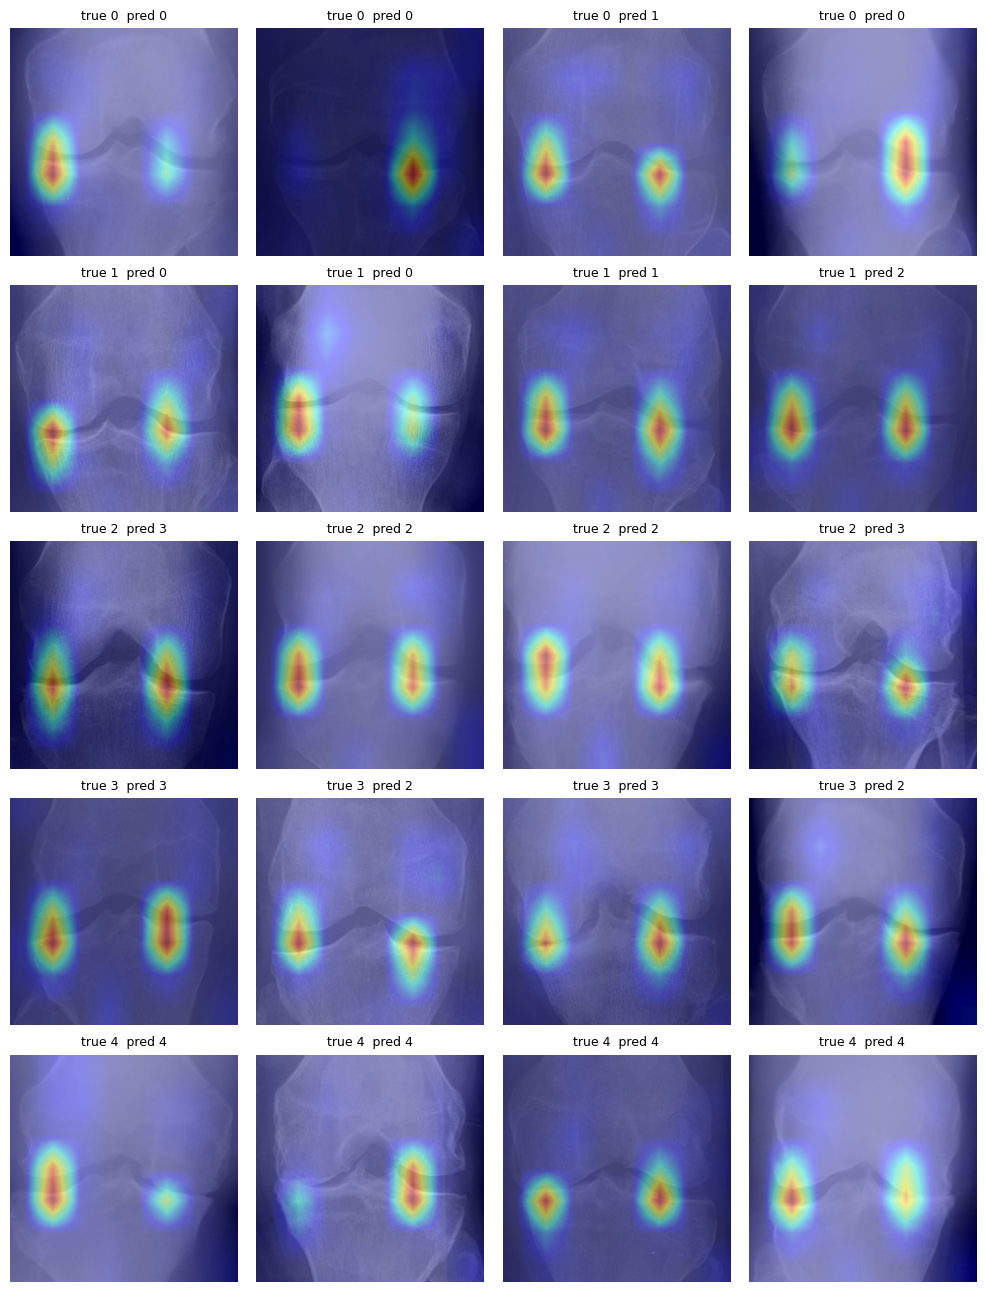

In [ ]:
import matplotlib.pyplot as plt

model.eval()
test = df[df["split"] == "test"]
fig, axes = plt.subplots(5, 4, figsize=(10, 13))

for kl in range(5):
    rows = test[test["kl"] == kl].head(4)
    for ax, (_, row) in zip(axes[kl], rows.iterrows()):
        picture = Image.open(row["path"]).convert("RGB").resize((224, 224))
        x = eval_tf(Image.open(row["path"]).convert("RGB"))[None].to(DEVICE)

        grade, cam = patch_heatmap(x)
        cam = F.interpolate(cam[None, None].cpu(), size=(224, 224), mode="bilinear")[0, 0]

        ax.imshow(picture)
        ax.imshow(cam, cmap="jet", alpha=0.4)
        ax.set_title(f"true {kl}  pred {grade}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

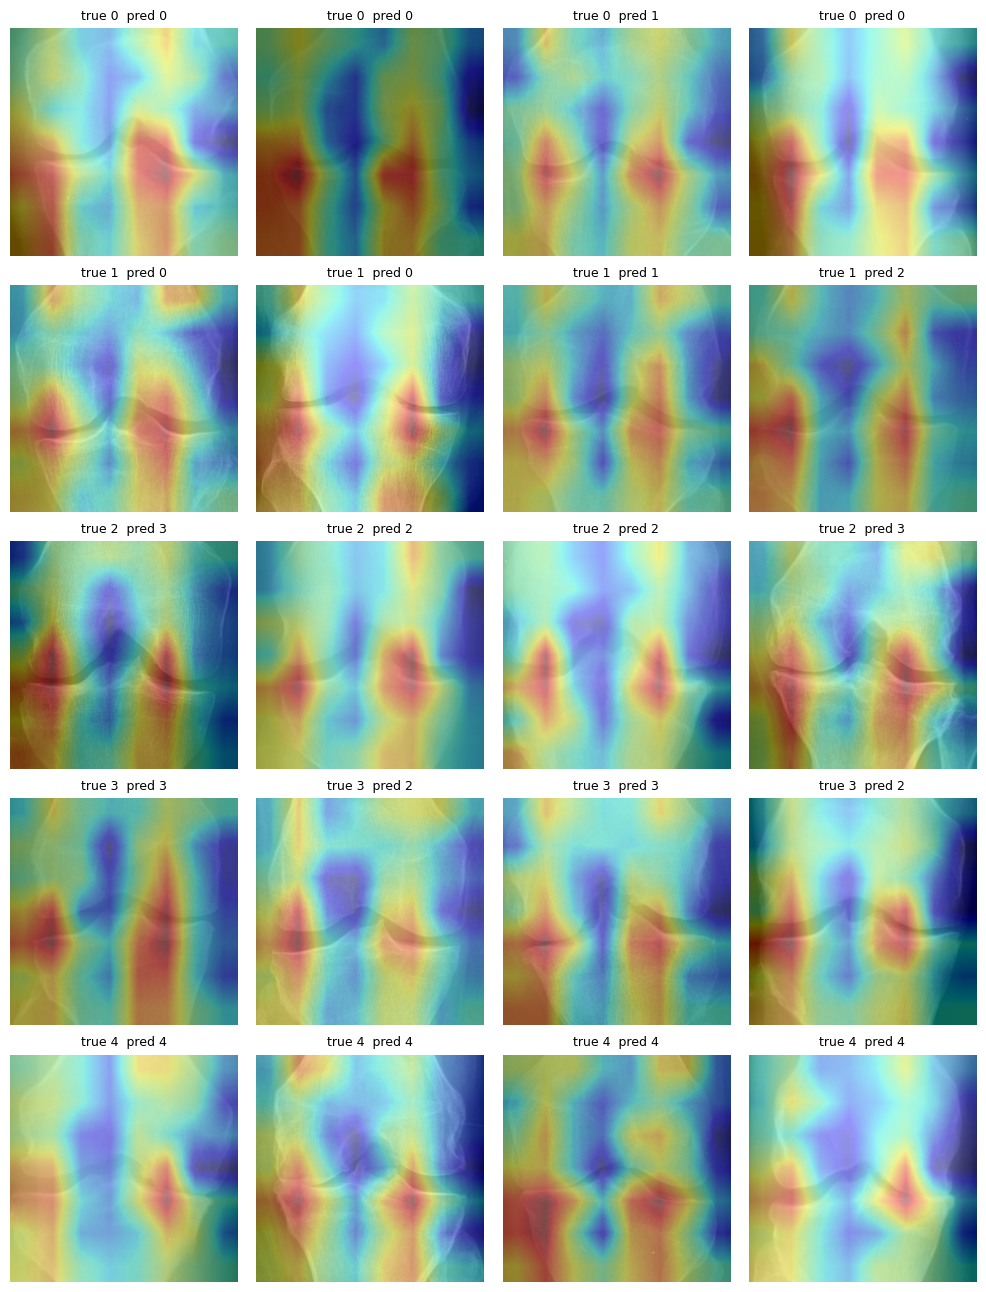

attention values across these 20 images: 0.132 to 0.903


In [ ]:
model.patch_net.layer4._forward_hooks.clear()      # remove the Grad-CAM hook first

# The spatial attention CBAM learned. No gradients: this is the map the model
# actually used in its decision, not one inferred afterwards.
model.attn_patch.spatial._forward_hooks.clear()
attn = {}

def grab_attn(module, inputs, output):
    attn["map"] = torch.sigmoid(output)

model.attn_patch.spatial.register_forward_hook(grab_attn)


def attention_map(image):
    with torch.no_grad():
        _, dist, _ = model(image)
    a = attn["map"][:, 0]                       # 2 halves, height, width
    return dist.argmax(1).item(), torch.cat([a[0], a[1]], dim=1).cpu()


test = df[df["split"] == "test"]
fig, axes = plt.subplots(5, 4, figsize=(10, 13))
lo, hi = 1.0, 0.0

for kl in range(5):
    rows = test[test["kl"] == kl].head(4)
    for ax, (_, row) in zip(axes[kl], rows.iterrows()):
        picture = Image.open(row["path"]).convert("RGB").resize((224, 224))
        x = eval_tf(Image.open(row["path"]).convert("RGB"))[None].to(DEVICE)

        grade, m = attention_map(x)
        lo, hi = min(lo, m.min().item()), max(hi, m.max().item())
        m = F.interpolate(m[None, None], size=(224, 224), mode="bilinear")[0, 0]

        ax.imshow(picture)
        ax.imshow(m, cmap="jet", alpha=0.4)
        ax.set_title(f"true {kl}  pred {grade}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()
print(f"attention values across these 20 images: {lo:.3f} to {hi:.3f}")

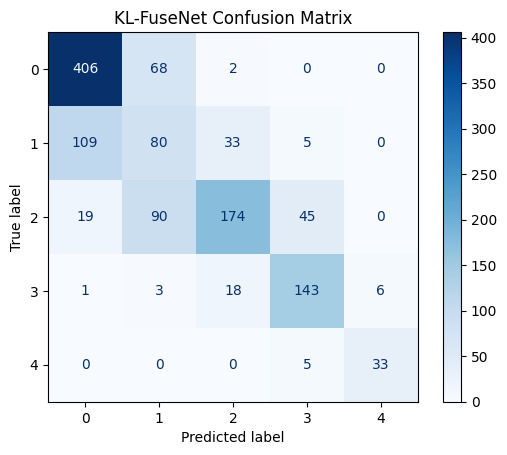

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])

ConfusionMatrixDisplay(cm, display_labels=[0, 1, 2, 3, 4]).plot(cmap="Blues")
plt.title("KL-FuseNet Confusion Matrix")
plt.show()

In [ ]:
# Grad-CAM on the ResNet stream, which sees each half of the image separately.
model.patch_net.layer4._forward_hooks.clear()
saved_patch = {}

def grab_patch(module, inputs, output):
    output.retain_grad()
    saved_patch["fmap"] = output

model.patch_net.layer4.register_forward_hook(grab_patch)


def patch_heatmap(image):
    """Heatmap from the ResNet stream. Returns the predicted grade and the map."""
    _, dist, _ = model(image)
    grade = dist.argmax(1).item()

    model.zero_grad()
    dist[0, grade].backward()

    fmap = saved_patch["fmap"]
    grads = saved_patch["fmap"].grad
    weight = grads.mean(dim=(2, 3))

    cam = (weight[:, :, None, None] * fmap).sum(1)
    cam = cam.abs()                                  # influence, whatever its sign
    both = torch.cat([cam[0], cam[1]], dim=1)        # glue left half to right half
    return grade, (both / both.max()).detach()

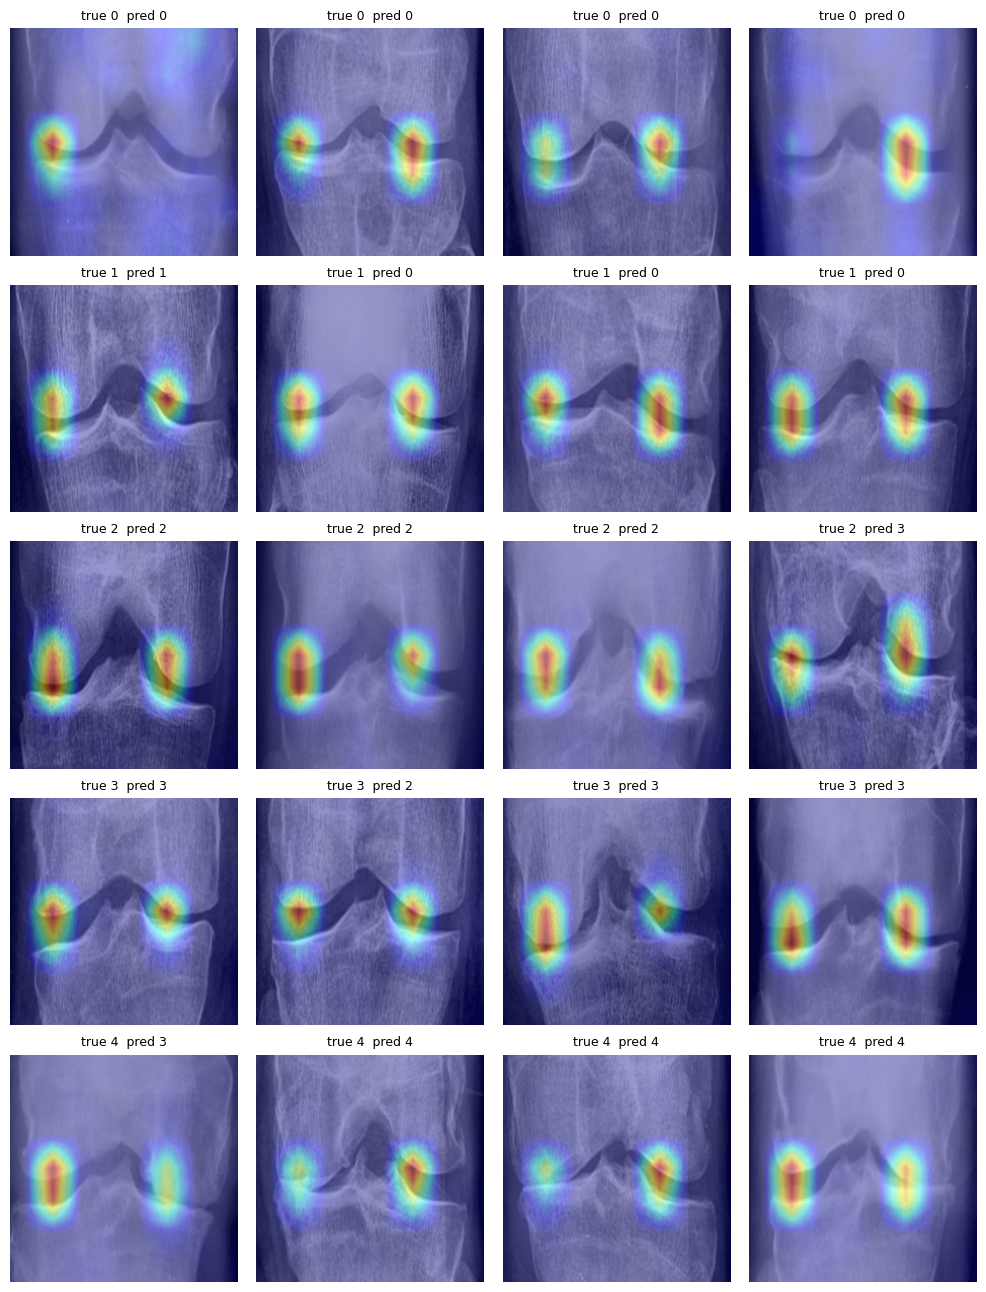

In [ ]:
model.eval()
test = df[df["split"] == "test"]
fig, axes = plt.subplots(5, 4, figsize=(10, 13))

for kl in range(5):
    rows = test[test["kl"] == kl].head(4)
    for ax, (_, row) in zip(axes[kl], rows.iterrows()):
        picture = eval_tf.transforms[0](Image.open(row["path"]).convert("RGB"))
        x = eval_tf(Image.open(row["path"]).convert("RGB"))[None].to(DEVICE)

        grade, cam = patch_heatmap(x)
        cam = F.interpolate(cam[None, None].cpu(), size=(224, 224), mode="bilinear")[0, 0]

        ax.imshow(picture)
        ax.imshow(cam, cmap="jet", alpha=0.4)
        ax.set_title(f"true {kl}  pred {grade}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
model.load_state_dict(torch.load("/content/drive/MyDrive/MUFSAL/run1/best.pt",
                                 map_location=DEVICE, weights_only=True))
model.eval()

base_tf = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

model.patch_net.layer3._forward_hooks.clear()
model.patch_net.layer4._forward_hooks.clear()
saved_patch = {}

def grab_patch(module, inputs, output):
    output.retain_grad()
    saved_patch["fmap"] = output

model.patch_net.layer3.register_forward_hook(grab_patch)


def patch_heatmap(image):
    _, dist, _ = model(image)
    grade = dist.argmax(1).item()

    model.zero_grad()
    dist[0, grade].backward()

    fmap = saved_patch["fmap"]
    grads = saved_patch["fmap"].grad
    weight = grads.mean(dim=(2, 3))

    cam = (weight[:, :, None, None] * fmap).sum(1).abs()
    both = torch.cat([cam[0], cam[1]], dim=1)
    return grade, (both / both.max()).detach()


print("done")

done


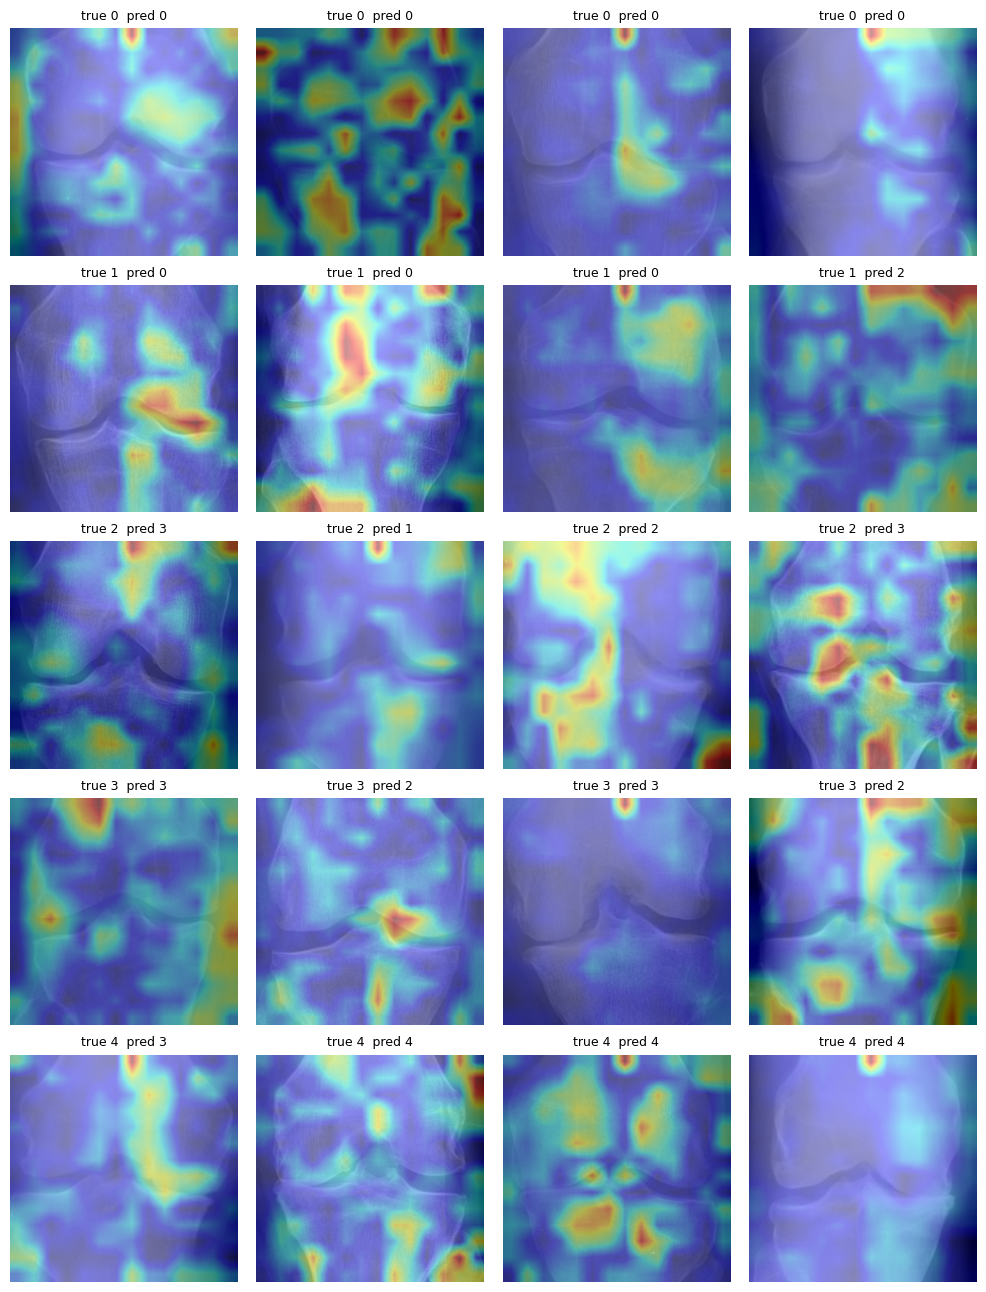

In [ ]:
test = df[df["split"] == "test"]
fig, axes = plt.subplots(5, 4, figsize=(10, 13))

for kl in range(5):
    rows = test[test["kl"] == kl].head(4)
    for ax, (_, row) in zip(axes[kl], rows.iterrows()):
        picture = Image.open(row["path"]).convert("RGB").resize((224, 224))
        x = base_tf(Image.open(row["path"]).convert("RGB"))[None].to(DEVICE)

        grade, cam = patch_heatmap(x)
        cam = F.interpolate(cam[None, None].cpu(), size=(224, 224), mode="bilinear")[0, 0]

        ax.imshow(picture)
        ax.imshow(cam, cmap="jet", alpha=0.4)
        ax.set_title(f"true {kl}  pred {grade}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

## 14. Test-time augmentation (TTA)
TTA makes several slightly changed versions of each test image, predicts each version, then averages the predictions. This can make predictions less sensitive to small image changes.

The paper describes eight views: the original image, a horizontal flip, and small rotations. Run this cell only after the basic test evaluation works. It takes longer.

In [ ]:
import torchvision.transforms.functional as TF
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Eight views: original, flipped, and rotations of +/-3, +/-5, +/-7 degrees.
def make_tta_views(x):
    views = [x, torch.flip(x, dims=[3])]
    for angle in [3, -3, 5, -5, 7, -7]:
        views.append(TF.affine(
            x, angle=angle, translate=[0, 0], scale=1.0,
            shear=[0.0, 0.0]
        ))
    return views

model.eval()
tta_true, tta_pred = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        all_ordinal_probs = []

        for view in make_tta_views(x):
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                ordinal_logits, _, _ = model(view)

            all_ordinal_probs.append(torch.sigmoid(ordinal_logits.float()))

        # Average the four threshold probabilities across the eight views.
        mean_probs = torch.stack(all_ordinal_probs).mean(dim=0)
        predictions = (mean_probs > 0.5).sum(dim=1)

        tta_true.extend(y.tolist())
        tta_pred.extend(predictions.cpu().tolist())

print("TTA accuracy:", round(accuracy_score(tta_true, tta_pred), 4))
print("TTA macro F1:", round(f1_score(tta_true, tta_pred, average="macro", zero_division=0), 4))
print("TTA QWK:", round(cohen_kappa_score(tta_true, tta_pred, weights="quadratic"), 4))


TTA accuracy: 0.6855
TTA macro F1: 0.6942
TTA QWK: 0.8569


## 15. Loading the trained model

**Does:** loads the saved weights and runs one pass over the validation set.

Nothing is trained from here on. We keep the distribution head because it gives a
probability per grade, which is what a confidence number is built from.


In [ ]:
from sklearn.metrics import cohen_kappa_score

# Load the trained weights. Nothing is trained here.
model.load_state_dict(torch.load(os.path.join(WORK_DIR, "best.pt"),
                                 map_location=DEVICE, weights_only=True))
model.eval()

# One pass over the validation set, keeping the two heads we need.
val_ordinal, val_dist, val_true = [], [], []
with torch.no_grad():
    for x, y in val_loader:
        o, d, _ = model(x.to(DEVICE))
        val_ordinal.append(o.float().cpu())
        val_dist.append(d.float().cpu())
        val_true.append(y)

val_ordinal = torch.cat(val_ordinal)
val_dist = torch.cat(val_dist)
val_true = torch.cat(val_true)

# Check: these weights should give back the validation QWK seen during training.
pred = (torch.sigmoid(val_ordinal) > 0.5).sum(1)
print("shapes:", tuple(val_dist.shape), tuple(val_true.shape))
print("validation QWK:", round(cohen_kappa_score(val_true, pred, weights="quadratic"), 4),
      " (training reported 0.8312)")

shapes: (1238, 5) (1238,)
validation QWK: 0.8295  (training reported 0.8312)


## 16. Temperature scaling

**Does:** finds one number, T, that rescales the probabilities.

**Not in the paper.** The paper's metrics measure which grade is predicted, not
how sure the model is. MUFSAL shows a confidence number, so we need this.

The raw model claims 46.5% certainty while being right 65.9% of the time. We
divide the scores by T before softmax and keep whichever T fits validation best.
T never changes the predicted grade, so accuracy is identical.

**T = 0.51**, below 1, meaning the model was UNDER-confident. The cause is in
section 9: the distribution head was trained on a bell curve, so it was taught to
spread its probabilities out.

In [ ]:
# Try every temperature and keep the one that fits validation best.
# T only rescales the probabilities; it never changes which grade is predicted.
temperatures = torch.arange(0.05, 3.01, 0.01)
losses = [F.cross_entropy(val_dist / t, val_true).item() for t in temperatures]

T = temperatures[torch.tensor(losses).argmin()].item()
print("best T:", round(T, 2))

for name, t in [("raw", 1.0), ("calibrated", T)]:
    probs = F.softmax(val_dist / t, dim=1)
    confidence = probs.max(1).values.mean()
    accuracy = (probs.argmax(1) == val_true).float().mean()
    print(f"{name:12s} says {confidence:.1%} sure, is right {accuracy:.1%} of the time")

best T: 0.51
raw          says 46.5% sure, is right 65.9% of the time
calibrated   says 59.8% sure, is right 65.9% of the time


## 17. Did the calibration work?

**Does:** groups predictions by confidence and checks each group's real accuracy.
ECE is the average gap, so lower is better.

ECE drops from 0.1974 to 0.0614. More useful: before, 1,100 of 1,238 images sat
in one band, so the number told us nothing. After, they split into 796 and 441
with real accuracies of 58.0% and 80.3% - the confidence now separates reliable
predictions from shaky ones.

In [ ]:
def reliability(logits, true, t, name):
    """Group predictions by how confident they are, and check each group."""
    probs = F.softmax(logits / t, dim=1)
    conf = probs.max(1).values
    correct = (probs.argmax(1) == true).float()

    print(f"\n{name}")
    print(f"{'confidence':>14} {'images':>8} {'says':>8} {'actually':>10}")
    ece = 0.0
    for lo in [0.0, 0.2, 0.4, 0.6, 0.8]:
        hi = lo + 0.2
        m = (conf > lo) & (conf <= hi)
        if m.sum() == 0:
            continue
        says, actually = conf[m].mean().item(), correct[m].mean().item()
        ece += (m.float().mean() * abs(says - actually)).item()
        print(f"{lo:.1f} - {hi:.1f}  {int(m.sum()):>10} {says:>8.1%} {actually:>10.1%}")
    print(f"calibration error (ECE): {ece:.4f}")


reliability(val_dist, val_true, 1.0, "raw (T = 1)")
reliability(val_dist, val_true, T, f"calibrated (T = {T})")


raw (T = 1)
    confidence   images     says   actually
0.2 - 0.4         138    37.2%      35.5%
0.4 - 0.6        1100    47.7%      69.7%
calibration error (ECE): 0.1974

calibrated (T = 0.5099999904632568)
    confidence   images     says   actually
0.2 - 0.4           1    38.7%       0.0%
0.4 - 0.6         796    53.7%      58.0%
0.6 - 0.8         441    70.9%      80.3%
calibration error (ECE): 0.0614


## 18. The three confidence numbers

**Does:** defines the function MUFSAL will call.

One number is not enough: on an ordinal scale, off by one grade is a small error
and off by three is serious.

- `exact` - the predicted grade on its own
- `within1` - that grade or either neighbour, the honest headline number
- `severe` - P(KL >= 2), where osteoarthritis becomes clinically significant

Grade 0 has no left neighbour and grade 4 no right one, so padding with a zero on
each side handles both edges with no special case.

In [ ]:
# Three confidence numbers per image, from the calibrated probabilities.
def confidence(logits, T):
    probs = F.softmax(logits / T, dim=1)
    grade = probs.argmax(1)

    exact = probs.gather(1, grade[:, None]).squeeze(1)      # P(this exact grade)

    # P(this grade or one grade either side).
    # The zero padding makes grade 0 and grade 4 work with no special case.
    padded = F.pad(probs, (1, 1))
    within1 = padded.gather(1, torch.stack([grade, grade + 1, grade + 2], 1)).sum(1)

    severe = probs[:, 2:].sum(1)                            # P(KL >= 2)
    return grade, exact, within1, severe


grade, exact, within1, severe = confidence(val_dist, T)

# Is the model honest? Compare what it claims with what really happens.
print(f"says exact    {exact.mean():.1%}   actually {(grade == val_true).float().mean():.1%}")
print(f"says within-1 {within1.mean():.1%}   actually {((grade - val_true).abs() <= 1).float().mean():.1%}")
print(f"P(KL>=2) mean {severe.mean():.1%}   actually {(val_true >= 2).float().mean():.1%}")

says exact    59.8%   actually 65.9%
says within-1 97.9%   actually 95.6%
P(KL>=2) mean 38.6%   actually 43.1%


In [ ]:
# Run every test image through the model and keep its 5 grade scores.
test_dist = []
test_true = []

with torch.no_grad():                                 # no training here, so no gradients
    for images, labels in test_loader:
        _, dist, _ = model(images.to(DEVICE))         # the model returns 3 things, we want the middle one
        test_dist.append(dist.float().cpu())
        test_true.append(labels)

test_dist = torch.cat(test_dist)                      # one table: 1240 rows x 5 grades
test_true = torch.cat(test_true)                      # the true grade of each image

print("shapes:", test_dist.shape, test_true.shape)

shapes: torch.Size([1240, 5]) torch.Size([1240])


In [ ]:
# The three confidence numbers for every test image.
grade, exact, within1, severe = confidence(test_dist, T)

# Honesty check: what the model claims, next to what really happens.
really_exact   = (grade == test_true).float().mean()            # got the grade spot on
really_within1 = ((grade - test_true).abs() <= 1).float().mean()  # off by one grade at most

print(f"exact      says {exact.mean():.1%}   really {really_exact:.1%}")
print(f"within-1   says {within1.mean():.1%}   really {really_within1:.1%}")

exact      says 60.7%   really 68.9%
within-1   says 97.9%   really 97.2%


## 19. Final results on the test set

**Does:** the three cells below run the confidence on the held-out test set.

T was chosen on validation only, so these numbers are honest.

Exact accuracy 68.9%. Within-one-grade: claims 97.9%, delivers 97.2% - the number
we show a doctor is trustworthy. ECE 0.2175 to 0.0821.

In [ ]:
# Calibration error on the test set, before and after the fix.
reliability(test_dist, test_true, 1.0, "raw")
reliability(test_dist, test_true, T, "calibrated")


raw
    confidence   images     says   actually
0.2 - 0.4         116    37.4%      46.6%
0.4 - 0.6        1124    48.1%      71.2%
calibration error (ECE): 0.2175

calibrated
    confidence   images     says   actually
0.4 - 0.6         773    54.3%      61.7%
0.6 - 0.8         467    71.2%      80.7%
calibration error (ECE): 0.0821
